In [1]:
import pandas as pd
import matplotlib as plt
from sklearn.preprocessing import StandardScaler

In [3]:
df =pd.read_csv("thyroid_dataset.csv")

In [4]:
df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [9]:
X=df.drop("Outlier_label",axis=1)
y=df["Outlier_label"]

In [10]:
X.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,lithium,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,61.0,6.0,23.0,87.0,26.0
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,29.0,15.0,61.0,96.0,64.0
2,0.16,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,29.0,19.0,58.0,103.0,56.0
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,114.0,3.0,24.0,61.0,39.0
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,49.0,3.0,5.0,116.0,4.0


In [11]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [12]:
X_scaled

array([[-2.34449113e-02,  1.50050924e+00, -3.94405319e-01, ...,
        -1.40951598e+00, -3.74590514e-02, -1.25859776e+00],
       [ 2.40791602e-03, -6.66440415e-01, -3.94405319e-01, ...,
        -6.57814578e-01,  2.27969782e-01, -5.68029663e-01],
       [-7.03031607e-02, -6.66440415e-01,  2.53546276e+00, ...,
        -7.17159426e-01,  4.34414431e-01, -7.13412420e-01],
       ...,
       [-2.99081181e-02, -6.66440415e-01, -3.94405319e-01, ...,
         6.08208844e-01,  7.58827450e-01,  2.49748343e-01],
       [ 7.25532113e-03,  1.50050924e+00, -3.94405319e-01, ...,
         2.32358141e-01, -7.96695877e-03,  4.67822478e-01],
       [-2.18291096e-02, -6.66440415e-01, -3.94405319e-01, ...,
        -2.48028670e-02,  8.05093192e-02,  1.22538431e-01]],
      shape=(6916, 21))

In [23]:
from sklearn.ensemble import IsolationForest
clf=IsolationForest(n_estimators=200,contamination=0.036,random_state=42)

In [24]:
labels=clf.fit_predict(X_scaled)

In [25]:
labels

array([ 1,  1, -1, ...,  1,  1,  1], shape=(6916,))

In [26]:
#  visualize
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)

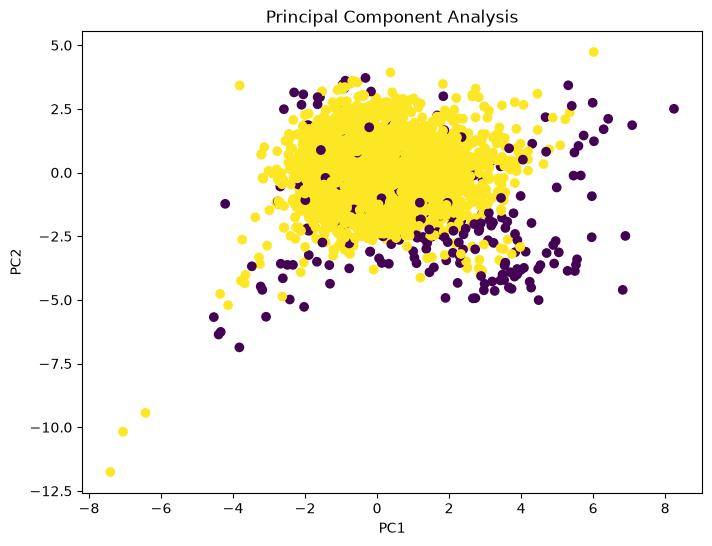

In [27]:
import matplotlib.pyplot as plt  # Import pyplot correctly

plt.figure(figsize=(8, 6))  # Set figure size

plt.scatter(
    X_pca[:, 0],  # First principal component
    X_pca[:, 1],  # Second principal component
    c=labels      # Color points using cluster labels
)

plt.xlabel("PC1")  # Label x-axis
plt.ylabel("PC2")  # Label y-axis
plt.title("Principal Component Analysis")  # Set title

plt.show()  # Display the plot

In [28]:
import numpy as np
n_outliers= np.sum(labels==-1)
n_normal= np.sum(labels==1)

print("Outlier:",n_outliers)
print("Normal:",n_normal)

Outlier: 249
Normal: 6667


# LOF

In [33]:
from sklearn.neighbors import LocalOutlierFactor
neighbs=LocalOutlierFactor(contamination=0.036)
labels=neighbs.fit_predict(X_scaled)

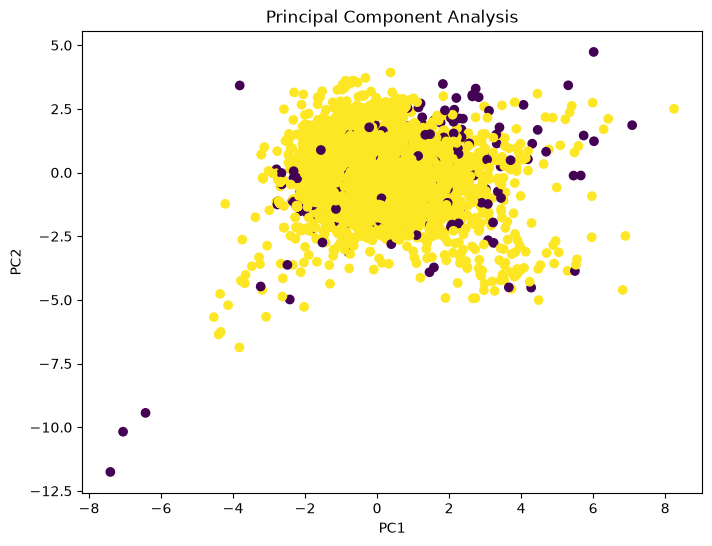

In [34]:
import matplotlib.pyplot as plt  # Import pyplot correctly

plt.figure(figsize=(8, 6))  # Set figure size

plt.scatter(
    X_pca[:, 0],  # First principal component
    X_pca[:, 1],  # Second principal component
    c=labels      # Color points using cluster labels
)

plt.xlabel("PC1")  # Label x-axis
plt.ylabel("PC2")  # Label y-axis
plt.title("Principal Component Analysis")  # Set title

plt.show()  # Display the plot

In [35]:
n_outliers= np.sum(labels==-1)
n_normal= np.sum(labels==1)

print("Outlier:",n_outliers)
print("Normal:",n_normal)

Outlier: 249
Normal: 6667
